# 5. Feature Engineering

## 1. Introduction

Feature Engineering is the process of creating or transforming
features to improve the predictive performance of Machine Learning
models.

The original dataset contains:

- Time
- V1 to V28
- Amount

In this project, additional logarithmic features will be generated
to investigate whether they improve the representation of
transaction amounts and elapsed time.

All transformations must be reproducible during model inference.

In [17]:
import pandas as pd
import numpy as np

from IPython.display import display

from src.config import (
    CLEANED_DATA_PATH,
    TARGET_COLUMN,
)

from src.feature_engineering import (
    FeatureEngineer,
    create_features,
)

df = pd.read_csv(CLEANED_DATA_PATH)

X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

print("Original Features Shape:", X.shape)

display(X.head())

Original Features Shape: (284807, 30)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99


## 2. Original Feature Analysis

Before creating additional features, the original features
are examined.

Amount and Time are selected for further investigation
because they represent transaction amount and elapsed time.

The logarithmic transformation may help represent highly
skewed numerical distributions.

In [18]:
display(
    X[["Amount", "Time"]].describe().T
)

print("Amount Skewness:", X["Amount"].skew())

print("Time Skewness:", X["Time"].skew())

,count,mean,std,min,25%,50%,75%,max
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00


Amount Skewness: 16.97772445376101
Time Skewness: -0.03556761800632094


## 3. Logarithmic Feature Transformation

The logarithmic transformation is applied using:

log1p(x) = log(1 + x)

This transformation is suitable for non-negative values
and can reduce the effect of strong right skewness.

The following features will be created:

1. Amount_log1p
2. Time_log1p

The original features will be preserved.

In [19]:
feature_engineer = FeatureEngineer(
    add_amount_log=True,
    add_time_log=True
)

X_engineered = feature_engineer.fit_transform(X)

print("Original Shape:", X.shape)

print("Engineered Shape:", X_engineered.shape)

display(X_engineered.head())

Original Shape: (284807, 30)
Engineered Shape: (284807, 32)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Amount_log1p,Time_log1p
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,5.014760,0.000000
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,1.305626,0.000000
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,5.939276,0.693147
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,4.824306,0.693147
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,4.262539,1.098612


In [20]:
new_features = [
    "Amount_log1p",
    "Time_log1p"
]

display(
    X_engineered[new_features].describe().T
)

assert "Amount_log1p" in X_engineered.columns

assert "Time_log1p" in X_engineered.columns

assert X_engineered.shape[1] == X.shape[1] + 2

print("Feature engineering verification passed.")

,count,mean,std,min,25%,50%,75%,max
Amount_log1p,284807.0,3.152188,1.656648,0.0,1.887070,3.135494,4.358822,10.153941
Time_log1p,284807.0,11.252433,0.818265,0.0,10.900482,11.346788,11.844539,12.059850


Feature engineering verification passed.


## 4. Comparing Original and Transformed Features

The original and transformed distributions are compared.

This analysis helps determine whether the logarithmic
transformation changes the distribution in a useful way.

The decision to retain transformed features should ultimately
be supported by validation performance.

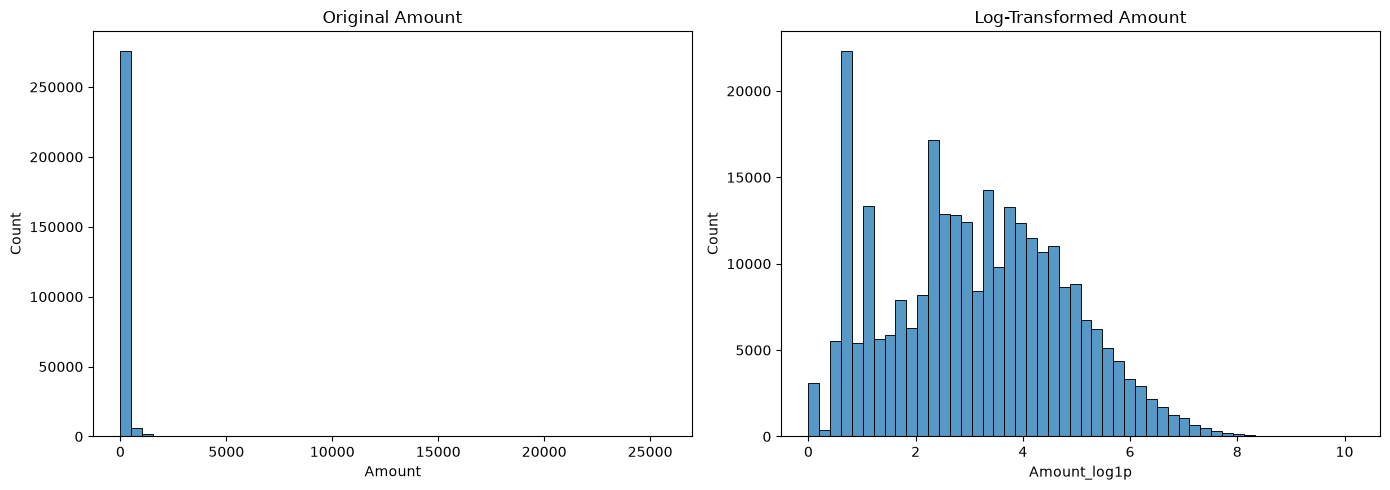

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.histplot(
    X["Amount"],
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Original Amount")

sns.histplot(
    X_engineered["Amount_log1p"],
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Log-Transformed Amount")

plt.tight_layout()

plt.show()

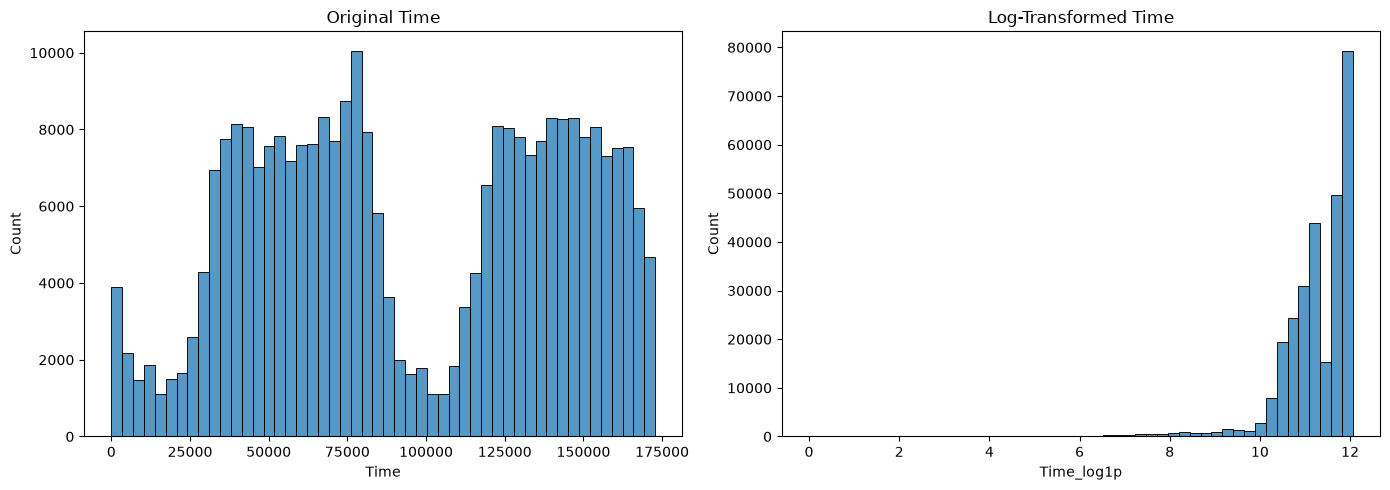

In [22]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.histplot(
    X["Time"],
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Original Time")

sns.histplot(
    X_engineered["Time_log1p"],
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Log-Transformed Time")

plt.tight_layout()

plt.show()

## 5. Feature Engineering Limitations

The Time feature represents elapsed time within the dataset.

It must not automatically be converted into:

- Hour of day
- Day of week
- Calendar date

These transformations require a real timestamp or a documented
mapping between elapsed time and calendar time.

A Time_Diff feature is also excluded from this version because
it depends on transaction ordering and previous observations.

The current transformations can be applied independently
to each new transaction.

## 6. Conclusion

The following additional features have been generated:

- Amount_log1p
- Time_log1p

The original features remain available.

The final decision regarding their usefulness will be based
on validation results rather than distribution plots alone.

In [23]:
print("Original Number of Features:", X.shape[1])

print("Engineered Number of Features:", X_engineered.shape[1])

print("\nNew Features:")

for feature in new_features:
    print(feature)

print("\nFinal Feature Names:")

print(X_engineered.columns.tolist())

Original Number of Features: 30
Engineered Number of Features: 32

New Features:
Amount_log1p
Time_log1p

Final Feature Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Amount_log1p', 'Time_log1p']
